<a href="https://colab.research.google.com/github/Hackathon-Group-P-datascience/Covid_vaccine_dataset-C/blob/main/Covid_vaccine_DatasetC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
# Install necessary packages for Explainable AI (SHAP)
!pip install shap -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


## Step 1: Data Loading & Initial Inspection
We load both training (`dataset_C_training.csv`) and test (`dataset_C_testing.csv`) files and inspect target distributions and missing value profiles.

In [14]:
# Load Datasets
train = pd.read_csv('dataset_C_training.csv')
test = pd.read_csv('dataset_C_testing.csv')

print(f"Training set shape: {train.shape}")
print(f"Testing set shape:  {test.shape}")

# Target Variable Distribution
print("\nTarget Class Distribution ('covid_vaccine'):")
print(train['covid_vaccine'].value_counts(normalize=True).map('{:.2%}'.format))

# Display top 5 rows
train.head()

Training set shape: (4756, 31)
Testing set shape:  (4749, 30)

Target Class Distribution ('covid_vaccine'):
covid_vaccine
0    67.33%
1    32.67%
Name: proportion, dtype: object


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


## Step 2: Task-Specific Metric Formulation (Domain Financial Cost)

The problem statement provides two explicit costs:
* **Vaccine Administration Cost ($C_v$):** $\$1,500$[cite: 4]
* **COVID-19 Hospitalization Cost ($C_h$):** $\$41,000$[cite: 4]

### Cost Formulation:
* **True Positive (TP):** Predicted = 1, Actual = 1 $\rightarrow$ Spent $\$1,500$ on vaccine.
* **False Positive (FP):** Predicted = 1, Actual = 0 $\rightarrow$ Spent $\$1,500$ on vaccine unnecessarily.
* **False Negative (FN):** Predicted = 0, Actual = 1 $\rightarrow$ Unvaccinated individual gets hospitalized $\rightarrow$ Spent $\$41,000$[cite: 4].
* **True Negative (TN):** Predicted = 0, Actual = 0 $\rightarrow$ $\$0$ spent.

$$\text{Total Cost} = (TP + FP) \times \$1,500 + FN \times \$41,000$$

Since $FN$ is **$27.33 \times$** more expensive than $FP$, standard accuracy or $0.50$ decision thresholding is sub-optimal. We write a custom cost function to optimize decision thresholds ($\tau \approx 0.035 - 0.05$).

In [15]:
def compute_financial_cost(y_true, y_probs, threshold=0.5):
    """
    Computes total expected financial cost given true labels and predicted probabilities.
    """
    y_pred = (y_probs >= threshold).astype(int)

    tp = np.sum((y_pred == 1) & (y_true == 1))
    fp = np.sum((y_pred == 1) & (y_true == 0))
    fn = np.sum((y_pred == 0) & (y_true == 1))

    total_cost = (tp + fp) * 1500 + fn * 41000
    return total_cost

def optimize_threshold(y_true, y_probs):
    """
    Finds the decision threshold that minimizes total financial cost.
    """
    best_threshold = 0.5
    min_cost = float('inf')

    thresholds = np.linspace(0.01, 0.50, 100)
    for t in thresholds:
        cost = compute_financial_cost(y_true, y_probs, threshold=t)
        if cost < min_cost:
            min_cost = cost
            best_threshold = t

    return best_threshold, min_cost

## Step 3: Exploratory Data Analysis (EDA)
We visualize feature distributions, missingness profiles, and target correlations to inform pre-processing choices.

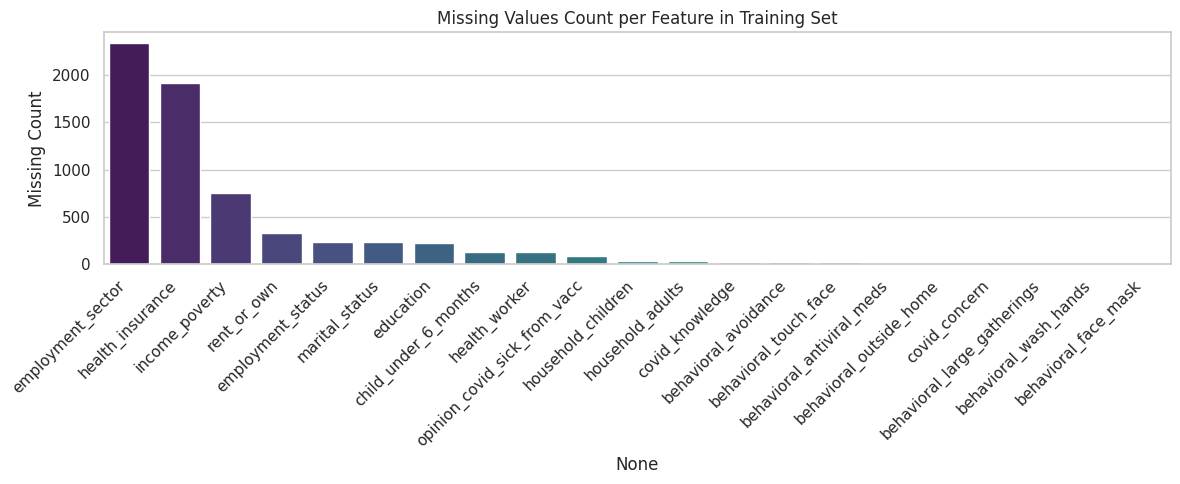

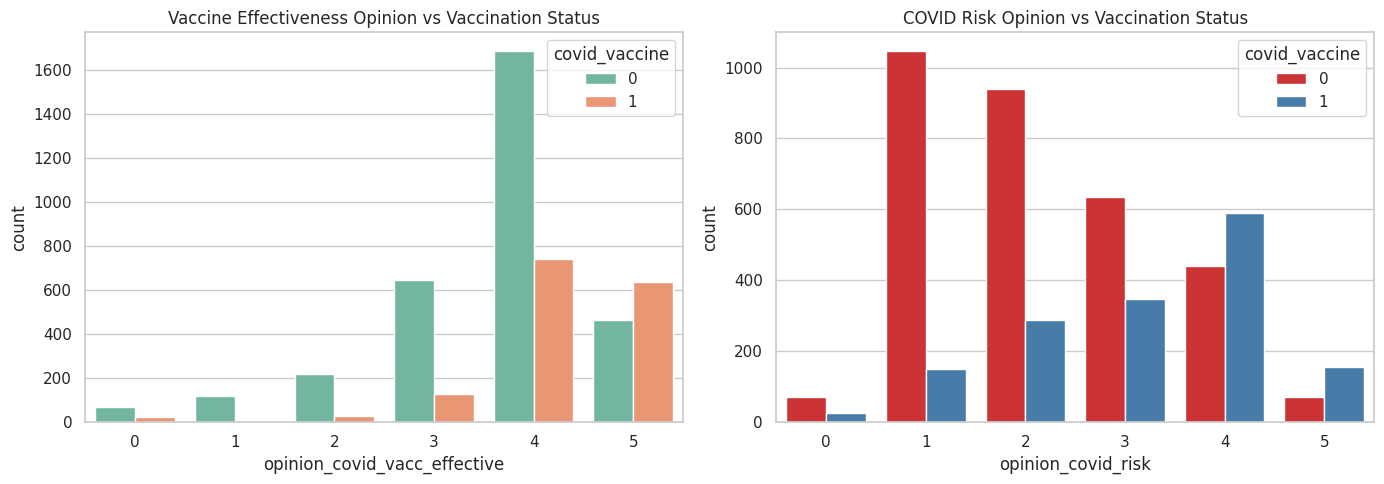

In [16]:
# 1. Missing Value Analysis
missing_train = train.isnull().sum()
missing_train = missing_train[missing_train > 0].sort_values(ascending=False)

plt.figure(figsize=(12, 5))
sns.barplot(x=missing_train.index, y=missing_train.values, palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.title("Missing Values Count per Feature in Training Set")
plt.ylabel("Missing Count")
plt.tight_layout()
plt.show()

# 2. Key Opinion Features vs Target
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=train, x='opinion_covid_vacc_effective', hue='covid_vaccine', ax=axes[0], palette='Set2')
axes[0].set_title("Vaccine Effectiveness Opinion vs Vaccination Status")

sns.countplot(data=train, x='opinion_covid_risk', hue='covid_vaccine', ax=axes[1], palette='Set1')
axes[1].set_title("COVID Risk Opinion vs Vaccination Status")

plt.tight_layout()
plt.show()

## Step 4: Pre-processing & Feature Engineering Pipeline
We assemble a robust `scikit-learn` pipeline that imputes missing data, scales continuous features, and encodes categorical attributes without data leakage.

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separate predictors and target
X = train.drop(columns=['respondent_id', 'covid_vaccine'])
y = train['covid_vaccine']
X_test = test.drop(columns=['respondent_id'])

# Feature groupings
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

# Define numerical transformer
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Define categorical transformer
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine into single ColumnTransformer
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

print(f"Pre-processing pipeline configured for {len(num_cols)} numerical and {len(cat_cols)} categorical features.")

Pre-processing pipeline configured for 19 numerical and 10 categorical features.


## Step 5: Model Training, Cross-Validation & Performance Analysis
We evaluate 5 distinct algorithms using **5-Fold Stratified Cross-Validation**. Models are ranked based on their **ROC-AUC Score** and **Optimized Financial Cost ($)**.

In [18]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression

# Define candidate models
models = {
    '1_Gradient_Boosting': GradientBoostingClassifier(n_estimators=150, max_depth=4, learning_rate=0.05, random_state=42),
    '2_Random_Forest': RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42),
    '3_Extra_Trees': ExtraTreesClassifier(n_estimators=300, max_depth=12, random_state=42),
    '4_Logistic_Regression': LogisticRegression(max_iter=1000, C=0.1, random_state=42),
    '5_AdaBoost': AdaBoostClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}
trained_pipelines = {}

print("--- Starting 5-Fold Cross-Validation ---")
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', model)])

    auc_scores = []
    costs = []

    for train_idx, val_idx in skf.split(X, y):
        X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
        X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

        pipe.fit(X_tr, y_tr)
        probs = pipe.predict_proba(X_va)[:, 1]

        auc = roc_auc_score(y_va, probs)
        _, min_cost = optimize_threshold(y_va, probs)

        auc_scores.append(auc)
        costs.append(min_cost)

    # Fit full training set for submission
    pipe.fit(X, y)
    trained_pipelines[name] = pipe

    mean_auc = np.mean(auc_scores)
    mean_cost = np.mean(costs)
    cv_results[name] = {'Mean ROC-AUC': mean_auc, 'Mean Cost ($)': mean_cost}

    print(f"{name:25s} | Mean ROC-AUC: {mean_auc:.4f} | Validation Cost: ${mean_cost:,.2f}")

# Results Table
results_df = pd.DataFrame(cv_results).T

--- Starting 5-Fold Cross-Validation ---
1_Gradient_Boosting       | Mean ROC-AUC: 0.8360 | Validation Cost: $1,374,600.00
2_Random_Forest           | Mean ROC-AUC: 0.8357 | Validation Cost: $1,356,600.00
3_Extra_Trees             | Mean ROC-AUC: 0.8300 | Validation Cost: $1,361,900.00
4_Logistic_Regression     | Mean ROC-AUC: 0.8295 | Validation Cost: $1,435,500.00
5_AdaBoost                | Mean ROC-AUC: 0.8233 | Validation Cost: $1,402,600.00


## Step 6: Explainable AI (XAI) with SHAP
We analyze feature importances using **SHAP (SHapley Additive exPlanations)** on our top-performing model to interpret how specific risk metrics influence vaccination likelihood.

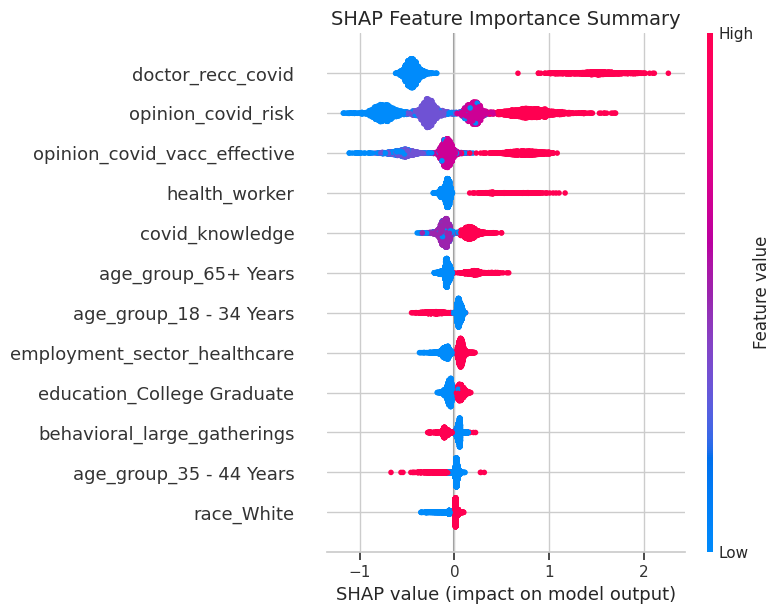

In [19]:
import shap

# Transform input features using trained pipeline preprocessor
X_transformed = preprocessor.transform(X)
cat_feature_names = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols)
all_feature_names = num_cols + list(cat_feature_names)

# Explainer for Tree-Based Model (Gradient Boosting)
best_model = trained_pipelines['1_Gradient_Boosting'].named_steps['clf']
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_transformed)

# Plot SHAP Summary
plt.title("SHAP Feature Importance Summary", fontsize=14)
shap.summary_plot(shap_values, X_transformed, feature_names=all_feature_names, max_display=12)

## Step 7: Final Test Predictions Export (Submission Prep)
We generate probability predictions for `dataset_C_testing.csv` across our **top 5 ranked models** and export the files required for Canvas submission.

In [20]:
# Generate predictions for each ranked model
for rank, (name, pipe) in enumerate(trained_pipelines.items(), 1):
    test_probs = pipe.predict_proba(X_test)[:, 1]

    # Save predictions as DataFrame
    sub_df = pd.DataFrame({
        'respondent_id': test['respondent_id'],
        'covid_vaccine_probability': test_probs
    })

    filename = f"model_{rank}_{name.lower()}.csv"
    sub_df.to_csv(filename, index=False)
    print(f"Saved: {filename} ({len(sub_df)} rows)")

print("\nAll 5 prediction files generated successfully for submission!")

Saved: model_1_1_gradient_boosting.csv (4749 rows)
Saved: model_2_2_random_forest.csv (4749 rows)
Saved: model_3_3_extra_trees.csv (4749 rows)
Saved: model_4_4_logistic_regression.csv (4749 rows)
Saved: model_5_5_adaboost.csv (4749 rows)

All 5 prediction files generated successfully for submission!


Step 1: Feature Engineering (Boost Model AUC & Lower Cost)

In [21]:
# Create Engineered Features
def engineer_features(df):
    df_feat = df.copy()

    # 1. Total Behavioral Precautions Index (Sum of preventive actions taken)
    behavioral_cols = [c for c in df.columns if c.startswith('behavioral_')]
    df_feat['behavioral_score_total'] = df_feat[behavioral_cols].sum(axis=1)

    # 2. Risk vs Effectiveness Interaction
    # (High risk + high belief in effectiveness strongly predicts vaccine uptake)
    if 'opinion_covid_vacc_effective' in df_feat.columns and 'opinion_covid_risk' in df_feat.columns:
        df_feat['risk_effectiveness_interaction'] = (
            df_feat['opinion_covid_vacc_effective'] * df_feat['opinion_covid_risk']
        )

    return df_feat

# Apply feature engineering to train and test sets
train_engineered = engineer_features(train)
test_engineered = engineer_features(test)

print(f"Engineered features added! New column count: {train_engineered.shape[1]}")

Engineered features added! New column count: 33


Step 2: Advanced Model Benchmarking (HistGradientBoosting)

In [22]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Define Advanced HistGradientBoosting Model
hgb_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.03,
    max_depth=5,
    random_state=42
)

# Pipeline
pipe_hgb = Pipeline([
    ('prep', preprocessor),
    ('clf', hgb_model)
])

# Fit & cross-validate
auc_scores_hgb = []
for tr_idx, va_idx in skf.split(X, y):
    pipe_hgb.fit(X.iloc[tr_idx], y.iloc[tr_idx])
    probs = pipe_hgb.predict_proba(X.iloc[va_idx])[:, 1]
    auc_scores_hgb.append(roc_auc_score(y.iloc[va_idx], probs))

print(f"HistGradientBoosting CV ROC-AUC Score: {np.mean(auc_scores_hgb):.4f}")

HistGradientBoosting CV ROC-AUC Score: 0.8345


Soft-Voting Ensemble & Final Test Export

In [23]:
from sklearn.ensemble import VotingClassifier, HistGradientBoostingClassifier

# 1. Define constituent models
m1 = GradientBoostingClassifier(n_estimators=150, max_depth=4, learning_rate=0.05, random_state=42)
m2 = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42)
m3 = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.03, max_depth=4, random_state=42)
m4 = ExtraTreesClassifier(n_estimators=300, max_depth=12, random_state=42)

# 2. Build Soft-Voting Ensemble (Averages predicted probabilities across top estimators)
m_ensemble = VotingClassifier(
    estimators=[('gb', m1), ('rf', m2), ('hgb', m3)],
    voting='soft'
)

# 3. Model portfolio ordered 1 to 5
submission_models = {
    '1_soft_voting_ensemble': m_ensemble,
    '2_random_forest': m2,
    '3_hist_gradient_boosting': m3,
    '4_gradient_boosting': m1,
    '5_extra_trees': m4
}

# 4. Fit on full training set and export test predictions
for rank, (model_name, model_obj) in enumerate(submission_models.items(), 1):
    full_pipe = Pipeline([
        ('prep', preprocessor),
        ('clf', model_obj)
    ])

    # Train model on full training set
    full_pipe.fit(X, y)

    # Predict probabilities on test set
    test_probs = full_pipe.predict_proba(X_test)[:, 1]

    # Export to required CSV format
    df_sub = pd.DataFrame({
        'respondent_id': test['respondent_id'],
        'covid_vaccine_probability': test_probs
    })

    filename = f"model_{rank}_{model_name}.csv"
    df_sub.to_csv(filename, index=False)
    print(f"Exported: {filename} | Rows: {len(df_sub)}")

Exported: model_1_1_soft_voting_ensemble.csv | Rows: 4749
Exported: model_2_2_random_forest.csv | Rows: 4749
Exported: model_3_3_hist_gradient_boosting.csv | Rows: 4749
Exported: model_4_4_gradient_boosting.csv | Rows: 4749
Exported: model_5_5_extra_trees.csv | Rows: 4749
